LIBRERIE UTILIZZATE

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import math



##CARICAMETO DEI DATI

In [4]:
import kagglehub
import os


# 1. Scarichiamo l'ultima versione del dataset inserendo l'handle corretto
# Nota: kagglehub permette il download di dataset pubblici senza richiedere API key
path = kagglehub.dataset_download("shubham2703/smartphone-retail-outlet-sales-data")
print("Percorso dei file del dataset:", path)

# 2. Cerchiamo dinamicamente il file CSV all'interno della cartella scaricata
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]

if csv_files:
    # 3. Costruiamo il percorso completo e carichiamo il primo CSV trovato
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    
    print(f"Dataset '{csv_files[0]}' caricato con successo!")
    # Mostriamo le prime righe per verifica
    # print(df.head()) 
else:
    print("Errore: Nessun file CSV trovato all'interno del dataset.")

c:\Users\santo\Desktop\Master MIA\Data Visual\Report vendite 2018 - 2023\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 46.1k/46.1k [00:00<00:00, 15.8MB/s]

Extracting files...
Percorso dei file del dataset: C:\Users\santo\.cache\kagglehub\datasets\shubham2703\smartphone-retail-outlet-sales-data\versions\7
Dataset 'SMARTPHONE RETAIL OUTLET SALE DATA.csv' caricato con successo!


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6421 entries, 0 to 6420
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      6421 non-null   str    
 1   F.Y                       6421 non-null   str    
 2   QUARTER                   6421 non-null   int64  
 3   P_NO                      6420 non-null   str    
 4   PAYMENT TYPE              6421 non-null   str    
 5   TYPE OF PRODUCT           6421 non-null   str    
 6   Quantity                  6421 non-null   int64  
 7   Price                     6421 non-null   float64
 8   Amount                    6421 non-null   float64
 9   TYPE OF ACCESSORY/MOBILE  6421 non-null   str    
dtypes: float64(2), int64(2), str(6)
memory usage: 834.7 KB


In [6]:
# Trovare il TYPE OF PRODUCT  con P_NO null
codice_mancante = df.loc[df['P_NO'].isnull(), 'TYPE OF PRODUCT']
print(codice_mancante)


2965    ACCESSORY
Name: TYPE OF PRODUCT, dtype: str


Alanlizzando il csv possiamo già vedere notiamo che c'è un codice prodotto mancante,ma la transazione (Amount) è avvenutaè anche la TYPE sia di categoria che di sottocategoria ha valore quindi il valore lo teniamo

#Analisi Vendite: CATEGORIE, CODICE PRODOTTO

In [7]:
Tot_prod_per_tipo = df['TYPE OF PRODUCT'].value_counts()
print(Tot_prod_per_tipo)

TYPE OF PRODUCT
MOBILE       4985
ACCESSORY    1293
TABLET        143
Name: count, dtype: int64


In [8]:
print(df['P_NO'].value_counts())


P_NO
P/M/A59    298
P/M/A10    276
P/M/A64    256
P/A/47     235
P/M/A20    177
          ... 
P/A/23       1
P/M/A30      1
P/A/42       1
P/A/31       1
P/M/A51      1
Name: count, Length: 144, dtype: int64


In [9]:
tot_vend_prod = df.groupby('P_NO')['Quantity'].sum().sort_values(ascending=False)
total_quantity = df['Quantity'].sum()
print(tot_vend_prod, "\n\nIl totale della quantità venduta è:", total_quantity)

P_NO
P/M/A59    305
P/M/A10    281
P/M/A64    262
P/A/47     245
P/M/A29    224
          ... 
P/A/42       1
P/M/A30      1
P/A/31       1
P/A/32       1
P/M/A51      1
Name: Quantity, Length: 144, dtype: int64 

Il totale della quantità venduta è: 6795


In [10]:
#Identificanzione della cumulazione
cum = tot_vend_prod.cumsum()
soglia = total_quantity * 0.8
print(tot_vend_prod[cum <= soglia],
      cum[cum <= soglia].count(), 
      "prodotti coprono l'80% delle vendite")

P_NO
P/M/A59    305
P/M/A10    281
P/M/A64    262
P/A/47     245
P/M/A29    224
P/M/A20    177
P/M/A24    176
P/A/22     174
P/M/A9     174
P/M/A14    171
P/A/35     170
P/M/A63    167
P/M/A23    166
P/M/A3     147
P/M/A1     143
P/M/A7     141
P/M/A55    126
P/M/A11    121
P/M/A75    118
P/M/A43    117
P/M/A8     101
P/M/A42     99
P/M/A12     94
P/M/A5      91
P/M/A57     84
P/M/A17     82
P/M/A13     82
P/A/21      81
P/M/A2      79
P/M/A67     78
P/M/A40     67
P/M/A62     66
P/M/A27     66
P/M/A46     64
P/M/A15     61
P/M/A22     61
P/A/41      56
P/M/A34     56
P/M/A60     55
P/M/A77     54
P/A/26      53
P/M/A45     51
P/T/S1      51
P/M/A4      50
P/A/44      48
P/M/A58     47
P/M/A33     47
Name: Quantity, dtype: int64 47 prodotti coprono l'80% delle vendite


In [11]:
tot_fatt_cat = df.groupby('TYPE OF PRODUCT')['Amount'].sum().sort_values(ascending=False)
total_fatturato = df['Amount'].sum()
print(tot_fatt_cat, "\n\nIl totale del fatturato è:", total_fatturato)

TYPE OF PRODUCT
MOBILE       1.151692e+08
ACCESSORY    5.499494e+06
TABLET       2.973920e+06
Name: Amount, dtype: float64 

Il totale del fatturato è: 123642572.81


#ANALISI METODI DI PAGAMENTO

In [12]:
metod_pay_fatt = df.groupby('PAYMENT TYPE')['Amount'].sum().sort_values(ascending=False)
print(metod_pay_fatt)

PAYMENT TYPE
DEBIT              38530691.07
MOBILE PAYMENTS    37305206.61
CREDIT             34440572.58
CASH               13366102.55
Name: Amount, dtype: float64


In [13]:
metod_pay_fav = df['PAYMENT TYPE'].value_counts()
print(metod_pay_fav)

PAYMENT TYPE
MOBILE PAYMENTS    1832
DEBIT              1787
CREDIT             1630
CASH               1172
Name: count, dtype: int64


In [14]:
percentuali = pd.crosstab(df['TYPE OF PRODUCT'], df['PAYMENT TYPE'], normalize='index')*100
print(percentuali.round(2))

PAYMENT TYPE      CASH  CREDIT  DEBIT  MOBILE PAYMENTS
TYPE OF PRODUCT                                       
ACCESSORY        27.30   23.67  22.27            26.76
MOBILE           15.63   25.90  29.43            29.05
TABLET           27.97   23.08  22.38            26.57


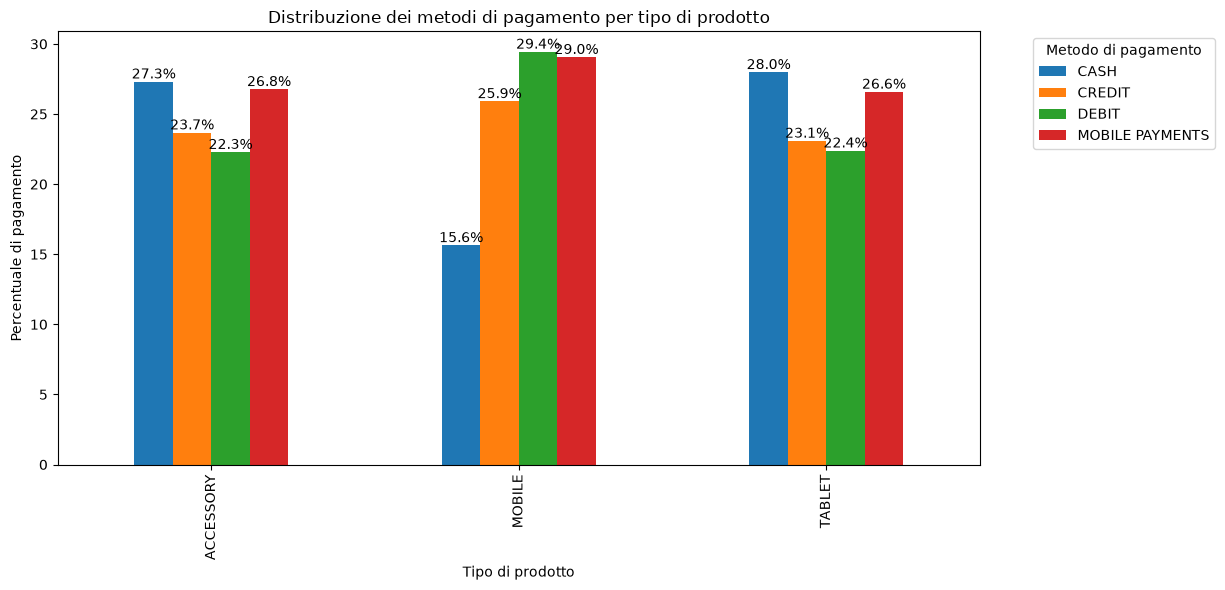

In [15]:
graf=percentuali.plot(kind='bar',
             figsize=(10, 6),
             legend=True,
             title='Distribuzione dei metodi di pagamento per tipo di prodotto')
plt.xlabel('Tipo di prodotto')
plt.ylabel('Percentuale di pagamento')
for container in graf.containers:
    graf.bar_label(container, label_type='edge', fmt='%.1f%%', fontsize=10, color='black')
plt.tight_layout()
plt.legend(title='Metodo di pagamento', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

#ANALISI SU ANNO MOBILE DEL FATTURATO E DELLE QUANTITA' VENDUTE

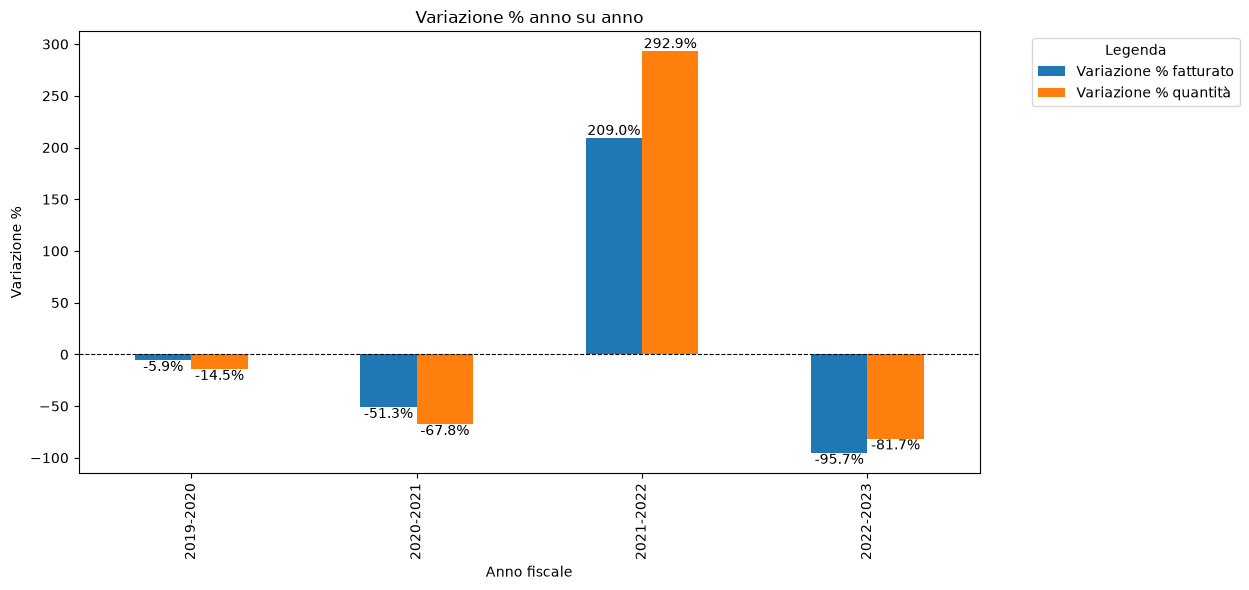

In [16]:
andamento_annuale = df.groupby('F.Y').agg({
    'Amount': 'sum',
    'Quantity': 'sum'
})

crescita_yoy = andamento_annuale.pct_change() * 100
crescita_yoy = crescita_yoy.dropna().rename(columns={'Amount': 'Variazione % fatturato', 'Quantity': 'Variazione % quantità'})

var_YoY = crescita_yoy.plot(kind='bar', figsize=(10, 6), title='Variazione % anno su anno')
var_YoY.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.xlabel('Anno fiscale')
plt.ylabel('Variazione %')
for container in var_YoY.containers:
    var_YoY.bar_label(container, label_type='edge', fmt='%.1f%%', fontsize=10, color='black')
plt.tight_layout()
plt.legend(title='Legenda', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [17]:
df['Date_parsed'] = pd.to_datetime(df['Date'], dayfirst=True)

In [18]:
#funzione che alll'intern degli YoY conta i mesi presnti
df['Mese'] = df['Date_parsed'].dt.to_period('M')
Conta_mese = df.groupby('F.Y')['Mese'].nunique()
print(Conta_mese)

F.Y
2018-2019    12
2019-2020    12
2020-2021     8
2021-2022    12
2022-2023     9
Name: Mese, dtype: int64


In [19]:
#Creazione del valore Booleano per capire se ci sono stati delle variazioni di prezzo
df['Prezzo_tipico'] = df.groupby('P_NO')['Price'].transform(lambda x: x.mode()[0])
df['Sconto_sospetto'] = df['Price'] < df['Prezzo_tipico']

In [20]:
#verificare quali prodotti hanno avuto sconti
sconti = df[df['Sconto_sospetto'] == True]

In [21]:
#scoprire per ogni prodotto quanti sconti sono stati applicati
sconti_per_prodotto = sconti.groupby('P_NO').size()
print(sconti_per_prodotto)

P_NO
P/A/1      2
P/A/12     1
P/A/13     8
P/A/14     2
P/A/15     2
          ..
P/M/A9     2
P/T/S1     3
P/T/S11    1
P/T/S4     6
P/T/S7     1
Length: 91, dtype: int64


In [22]:
sconti = df[df['Sconto_sospetto']].copy()
sconti['Mese'] = sconti['Date_parsed'].dt.to_period('M')
sconti_per_mese = sconti.groupby('Mese').size()
print(sconti_per_mese)

Mese
2018-04    34
2018-05    28
2018-06    23
2018-07    30
2018-08    66
2018-09    47
2018-10    34
2018-11    51
2018-12    49
2019-01    64
2019-02    42
2019-03    50
2019-04    27
2019-05    24
2019-06    29
2019-07    28
2019-08    39
2019-09    29
2019-10    28
2019-11    20
2019-12    18
2020-01    21
2020-02    17
2020-03    24
2020-06     5
2020-07    37
2020-08    23
2020-09    23
2020-10    16
2020-11    13
2020-12    11
2021-01    24
2021-04    11
2021-05    48
2021-06    52
2021-07    60
2021-08    77
2021-09    52
2021-10    30
2021-11    41
2021-12    42
2022-01    21
2022-02    17
2022-03    24
2022-04    11
2022-05    10
2022-06     6
2022-07    12
2022-08    16
2022-09    18
2022-10    20
2022-11    22
2022-12    17
Freq: M, dtype: int64


In [23]:
# prepara i dati per un'analisi/visualizzazione 
# dell'andamento temporale delle transazioni su base mensile.
df['Mese'] = df['Date_parsed'].dt.to_period('M')
transazioni_per_mese = df.groupby('Mese').size()

In [24]:
trans_con_sconto = sconti_per_mese.div(transazioni_per_mese) * 100
print(trans_con_sconto.sort_values(ascending=False))

Mese
2019-01    52.459016
2022-11    51.162791
2020-06    50.000000
2019-02    48.275862
2018-12    44.954128
2022-12    43.589744
2022-10    40.000000
2021-12    39.622642
2021-01    38.095238
2022-05    37.037037
2018-11    35.664336
2022-03    35.294118
2020-03    34.285714
2022-09    33.962264
2018-08    33.000000
2020-09    32.857143
2022-08    31.372549
2020-07    31.355932
2021-08    31.300813
2021-05    30.000000
2022-04    28.205128
2022-07    27.906977
2018-09    27.325581
2022-02    26.984127
2021-06    26.943005
2020-08    26.744186
2022-01    26.582278
2020-02    26.562500
2020-01    26.250000
2021-11    25.625000
2018-10    25.185185
2020-12    22.916667
2020-10    22.857143
2019-03    22.831050
2018-05    22.222222
2019-10    20.740741
2021-10    20.134228
2021-07    19.543974
2019-11    19.417476
2019-09    19.205298
2019-08    18.932039
2020-11    18.840580
2021-09    18.772563
2022-06    18.750000
2018-04    18.478261
2018-07    17.441860
2019-12    16.981132
2018-06 

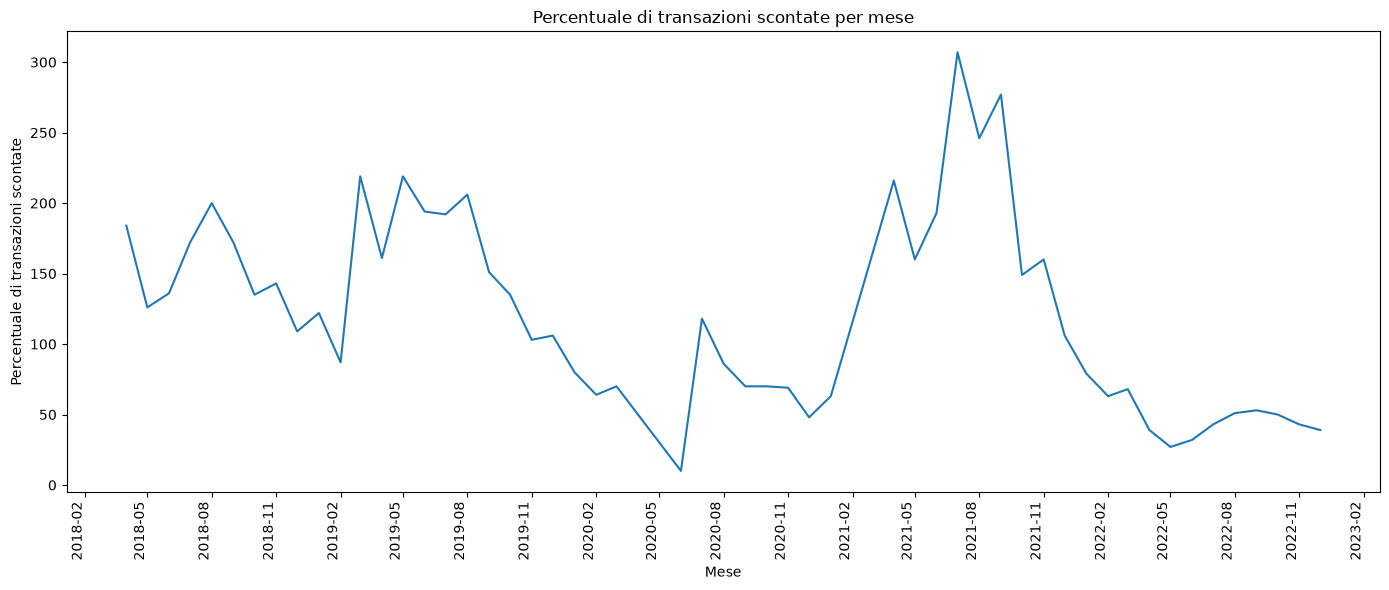

In [25]:
import matplotlib.dates as mdates

ax = transazioni_per_mese.plot(kind='line', figsize=(14, 6), x_compat=True, title='Percentuale di transazioni scontate per mese')

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

plt.xlabel('Mese')
plt.ylabel('Percentuale di transazioni scontate')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()